In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from scipy import stats

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

In [3]:
file_path = Path(
    "../05_Clean_Data/marketing_data_clean.csv"
)

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2240, 40)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Total_Purchases,Deal_Purchase_Issue,Total_Spending,Zero_Purchase_Spending_Issue,Has_Data_Quality_Issue,Data_Quality_Status,Income_Imputed,Education_Standardized,Marital_Status_Group,Customer_Age_Estimated,Age_Group,Income_Group
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,Spain,14,0,1190,0,0,No Flagged Issue,84835.0,Graduate,Divorced,44,35-44,High Income
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,Canada,17,0,577,0,0,No Flagged Issue,57091.0,Graduate,Single,53,45-54,Upper-Middle Income
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,USA,10,0,251,0,0,No Flagged Issue,67267.0,Graduate,Married,56,55-64,Upper-Middle Income
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,Australia,3,0,11,0,0,No Flagged Issue,32474.0,Graduate,Partnered,47,45-54,Low Income
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,Spain,6,0,91,0,0,No Flagged Issue,21474.0,Graduate,Single,25,25-34,Low Income


In [4]:
required_columns = [
    "Income",
    "Total_Spending",
    "Total_Purchases",
    "Recency",
    "Customer_Age_Estimated",
    "NumWebPurchases",
    "NumWebVisitsMonth",
    "Response"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("Missing Columns:", missing_columns)

Missing Columns: []


In [5]:
numeric_columns = [
    "Income",
    "Total_Spending",
    "Total_Purchases",
    "Recency",
    "Customer_Age_Estimated",
    "NumWebPurchases",
    "NumWebVisitsMonth"
]

In [6]:
descriptive_stats = (
    df[numeric_columns]
    .describe()
    .T
)

display(descriptive_stats.round(2))

,count,mean,std,min,25%,50%,75%,max
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.0,666666.0
Total_Spending,2240.0,605.80,602.25,5.0,68.75,396.0,1045.5,2525.0
Total_Purchases,2240.0,12.54,7.21,0.0,6.00,12.0,18.0,32.0
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.0,99.0
Customer_Age_Estimated,2240.0,45.19,11.98,18.0,37.00,44.0,55.0,121.0
NumWebPurchases,2240.0,4.08,2.78,0.0,2.00,4.0,6.0,27.0
NumWebVisitsMonth,2240.0,5.32,2.43,0.0,3.00,6.0,7.0,20.0


In [7]:
descriptive_stats["Median"] = (
    df[numeric_columns].median()
)

descriptive_stats["Skewness"] = (
    df[numeric_columns].skew()
)

display(descriptive_stats.round(2))

,count,mean,std,min,25%,50%,75%,max,Median,Skewness
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.0,666666.0,51381.5,6.76
Total_Spending,2240.0,605.80,602.25,5.0,68.75,396.0,1045.5,2525.0,396.0,0.86
Total_Purchases,2240.0,12.54,7.21,0.0,6.00,12.0,18.0,32.0,12.0,0.30
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.0,99.0,49.0,-0.00
Customer_Age_Estimated,2240.0,45.19,11.98,18.0,37.00,44.0,55.0,121.0,44.0,0.35
NumWebPurchases,2240.0,4.08,2.78,0.0,2.00,4.0,6.0,27.0,4.0,1.38
NumWebVisitsMonth,2240.0,5.32,2.43,0.0,3.00,6.0,7.0,20.0,6.0,0.21


In [8]:
pearson_corr = df[numeric_columns].corr(
    method="pearson"
)

display(pearson_corr.round(3))

,Income,Total_Spending,Total_Purchases,Recency,Customer_Age_Estimated,NumWebPurchases,NumWebVisitsMonth
Income,1.000,0.668,0.626,-0.004,0.162,0.388,-0.553
Total_Spending,0.668,1.000,0.821,0.020,0.111,0.520,-0.500
Total_Purchases,0.626,0.821,1.000,0.006,0.163,0.766,-0.426
Recency,-0.004,0.020,0.006,1.000,0.020,-0.011,-0.021
Customer_Age_Estimated,0.162,0.111,0.163,0.020,1.000,0.145,-0.121
NumWebPurchases,0.388,0.520,0.766,-0.011,0.145,1.000,-0.056
NumWebVisitsMonth,-0.553,-0.500,-0.426,-0.021,-0.121,-0.056,1.000


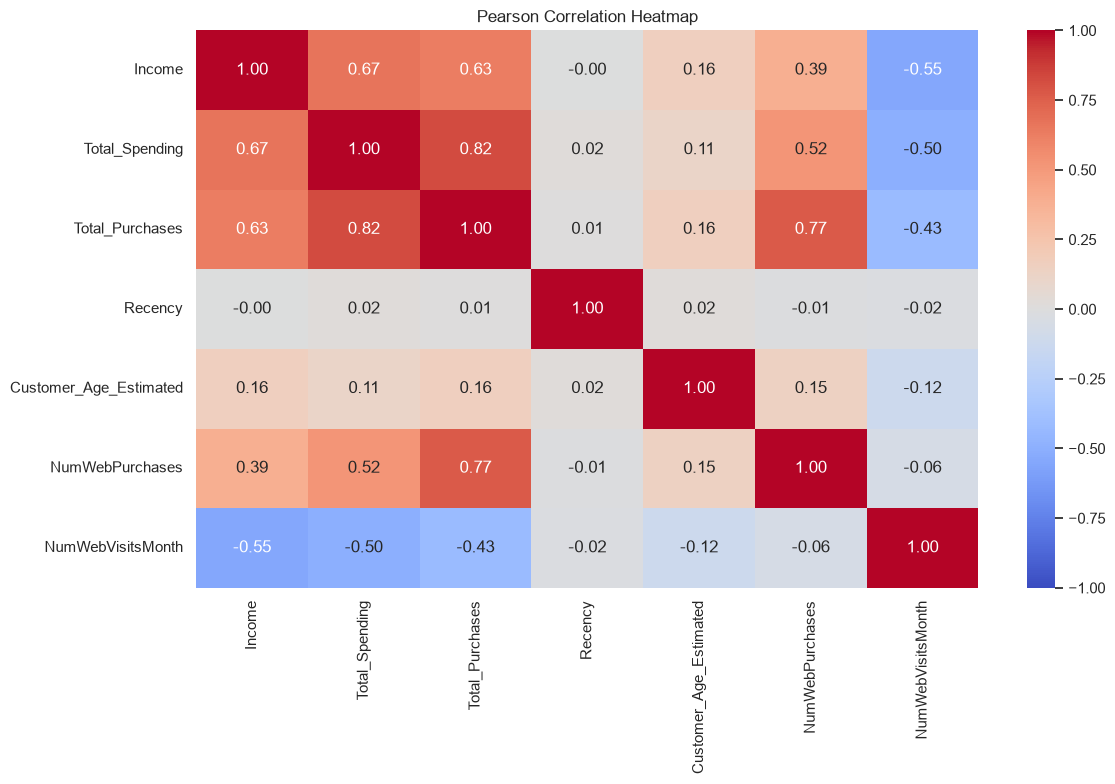

In [9]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Heatmap")

plt.tight_layout()
plt.show()

In [10]:
spearman_corr = df[numeric_columns].corr(
    method="spearman"
)

display(spearman_corr.round(3))

,Income,Total_Spending,Total_Purchases,Recency,Customer_Age_Estimated,NumWebPurchases,NumWebVisitsMonth
Income,1.000,0.851,0.778,0.008,0.217,0.573,-0.644
Total_Spending,0.851,1.000,0.908,0.020,0.157,0.727,-0.476
Total_Purchases,0.778,0.908,1.000,0.012,0.177,0.834,-0.420
Recency,0.008,0.020,0.012,1.000,0.021,-0.004,-0.022
Customer_Age_Estimated,0.217,0.157,0.177,0.021,1.000,0.164,-0.131
NumWebPurchases,0.573,0.727,0.834,-0.004,0.164,1.000,-0.097
NumWebVisitsMonth,-0.644,-0.476,-0.420,-0.022,-0.131,-0.097,1.000


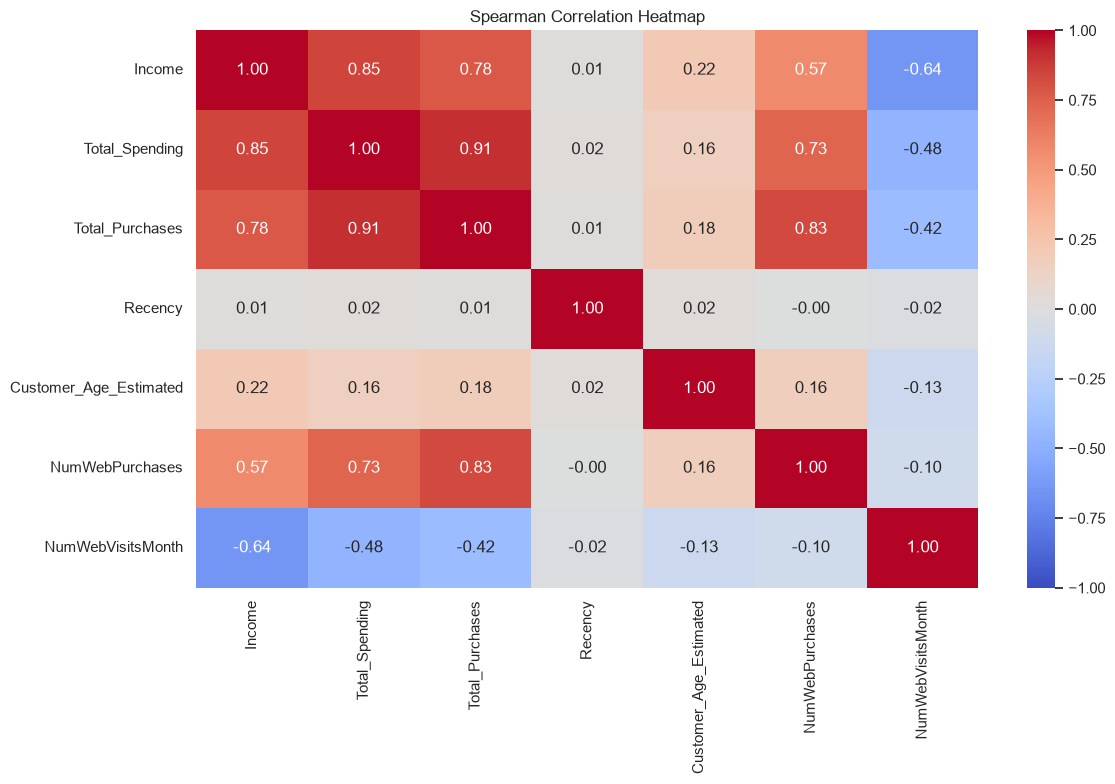

In [11]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Heatmap")

plt.tight_layout()
plt.show()

In [12]:
income_spending = df[
    ["Income", "Total_Spending"]
].dropna()

print("Valid Observations:", len(income_spending))

Valid Observations: 2216


In [13]:
pearson_r, pearson_p = stats.pearsonr(
    income_spending["Income"],
    income_spending["Total_Spending"]
)

spearman_r, spearman_p = stats.spearmanr(
    income_spending["Income"],
    income_spending["Total_Spending"]
)

print("Pearson Correlation:", round(pearson_r, 4))
print("Pearson p-value:", pearson_p)

print("Spearman Correlation:", round(spearman_r, 4))
print("Spearman p-value:", spearman_p)

Pearson Correlation: 0.6676
Pearson p-value: 5.843958806403454e-286
Spearman Correlation: 0.8509
Spearman p-value: 0.0


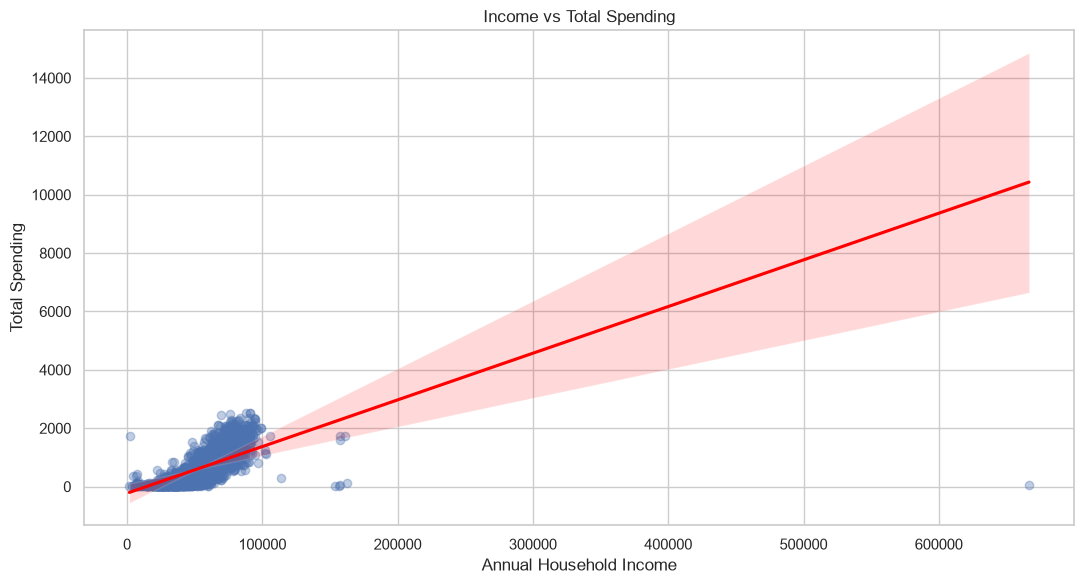

In [14]:
plt.figure(figsize=(11, 6))

sns.regplot(
    data=income_spending,
    x="Income",
    y="Total_Spending",
    scatter_kws={"alpha": 0.35},
    line_kws={"color": "red"}
)

plt.title("Income vs Total Spending")
plt.xlabel("Annual Household Income")
plt.ylabel("Total Spending")

plt.tight_layout()
plt.show()

In [15]:
Q1 = income_spending["Income"].quantile(0.25)
Q3 = income_spending["Income"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

income_without_outliers = income_spending[
    income_spending["Income"].between(lower, upper)
]

In [16]:
pearson_without_outliers = (
    income_without_outliers[
        ["Income", "Total_Spending"]
    ].corr(method="pearson").iloc[0, 1]
)

correlation_comparison = pd.DataFrame({
    "Scenario": [
        "Original Data",
        "Income IQR Outliers Excluded"
    ],
    "Pearson_Correlation": [
        pearson_r,
        pearson_without_outliers
    ],
    "Observations": [
        len(income_spending),
        len(income_without_outliers)
    ]
})

display(correlation_comparison.round(4))

,Scenario,Pearson_Correlation,Observations
0,Original Data,0.6676,2216
1,Income IQR Outliers Excluded,0.8236,2208


In [17]:
frequency_monetary = df[
    ["Total_Purchases", "Total_Spending"]
].dropna()

freq_corr, freq_p = stats.spearmanr(
    frequency_monetary["Total_Purchases"],
    frequency_monetary["Total_Spending"]
)

print("Spearman Correlation:", round(freq_corr, 4))
print("p-value:", freq_p)

Spearman Correlation: 0.9083
p-value: 0.0


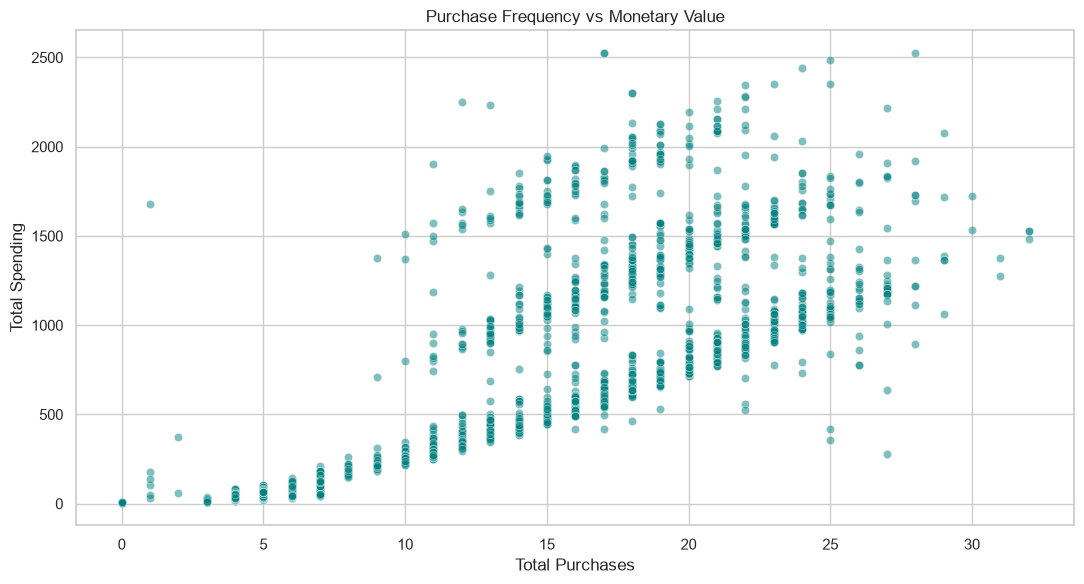

In [18]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=frequency_monetary,
    x="Total_Purchases",
    y="Total_Spending",
    alpha=0.5,
    color="teal"
)

plt.title("Purchase Frequency vs Monetary Value")
plt.xlabel("Total Purchases")
plt.ylabel("Total Spending")

plt.tight_layout()
plt.show()

In [19]:
recency_response = df[
    ["Recency", "Response"]
].dropna()

recency_corr, recency_p = stats.spearmanr(
    recency_response["Recency"],
    recency_response["Response"]
)

print("Spearman Correlation:", round(recency_corr, 4))
print("p-value:", recency_p)

Spearman Correlation: -0.1982
p-value: 2.855273354951666e-21


In [20]:
df["Recency_Group"] = pd.cut(
    df["Recency"],
    bins=[-1, 30, 60, 90, np.inf],
    labels=[
        "0-30 Days",
        "31-60 Days",
        "61-90 Days",
        "90+ Days"
    ]
)

In [21]:
recency_group_analysis = (
    df.groupby("Recency_Group", observed=True)
    .agg(
        Total_Customers=("ID", "nunique"),
        Response_Rate=("Response", "mean")
    )
    .reset_index()
)

recency_group_analysis["Response_Rate"] *= 100

display(recency_group_analysis.round(2))

,Recency_Group,Total_Customers,Response_Rate
0,0-30 Days,724,23.90
1,31-60 Days,654,13.61
2,61-90 Days,664,9.19
3,90+ Days,198,5.56


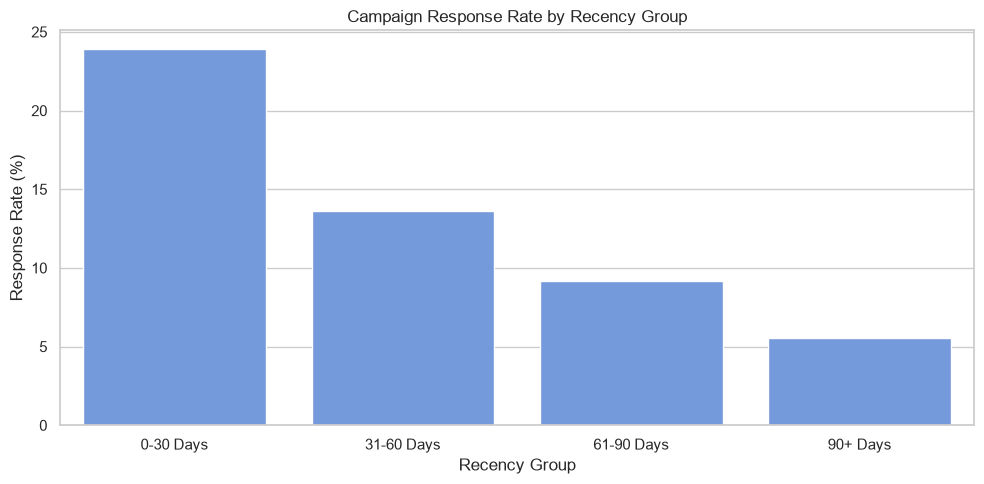

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=recency_group_analysis,
    x="Recency_Group",
    y="Response_Rate",
    color="cornflowerblue"
)

plt.title("Campaign Response Rate by Recency Group")
plt.xlabel("Recency Group")
plt.ylabel("Response Rate (%)")

plt.tight_layout()
plt.show()